In [1]:
# Importing Libraries
import os
import shutil
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import keras as k
from keras.models import Sequential
from keras.layers import Conv2D,Flatten,BatchNormalization,Activation,GlobalAveragePooling2D,Dropout,Dense,MaxPooling2D
from keras.callbacks import ReduceLROnPlateau, EarlyStopping
from PIL import Image
from tensorflow.keras.layers import Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.layers import SeparableConv2D
from tensorflow.keras.optimizers.schedules import ExponentialDecay
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

In [2]:
# Load dataset directories
test = r"Dataset\DATASET\test"
train = r"Dataset\DATASET\train"

In [3]:
img_size = (100, 100)
bth_size = 32

# Data augmentation for RGB training images
trdatagen = ImageDataGenerator(
    rescale=1.0/255,
    rotation_range=15,
    width_shift_range=0.15,
    height_shift_range=0.15,
    shear_range=0.15,
    zoom_range=0.15,
    horizontal_flip=True,
    validation_split=0.1
)

# Normalization for RGB test images
tedatagen = ImageDataGenerator(
    rescale=1.0/255
)

In [4]:
# Reading RGB training images

traingen = trdatagen.flow_from_directory(
    train,
    target_size=img_size,
    batch_size=bth_size,
    color_mode='rgb',          # CHANGED: RGB instead of grayscale
    class_mode='categorical',
    shuffle=True,
    subset='training'
)

# Reading RGB testing images

testgen = tedatagen.flow_from_directory(
    test,
    target_size=img_size,
    batch_size=bth_size,
    color_mode='rgb',          # CHANGED: RGB instead of grayscale
    class_mode='categorical',
    shuffle=False
)

Found 11046 images belonging to 7 classes.
Found 3068 images belonging to 7 classes.


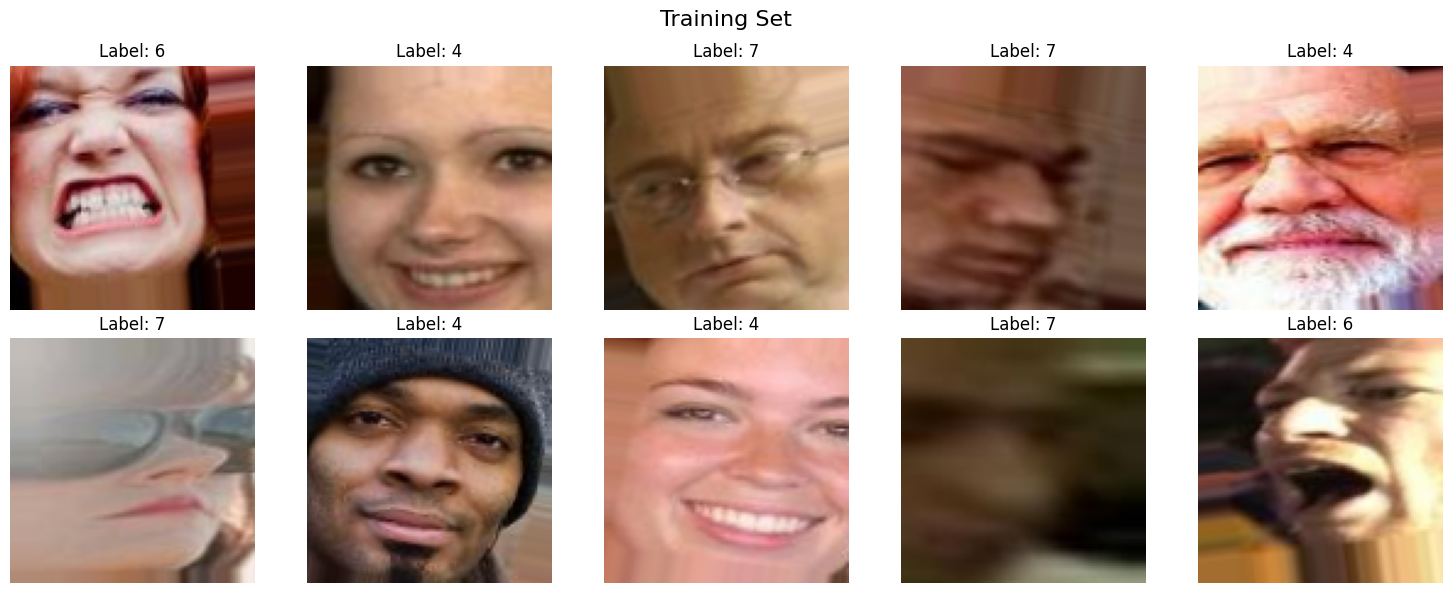

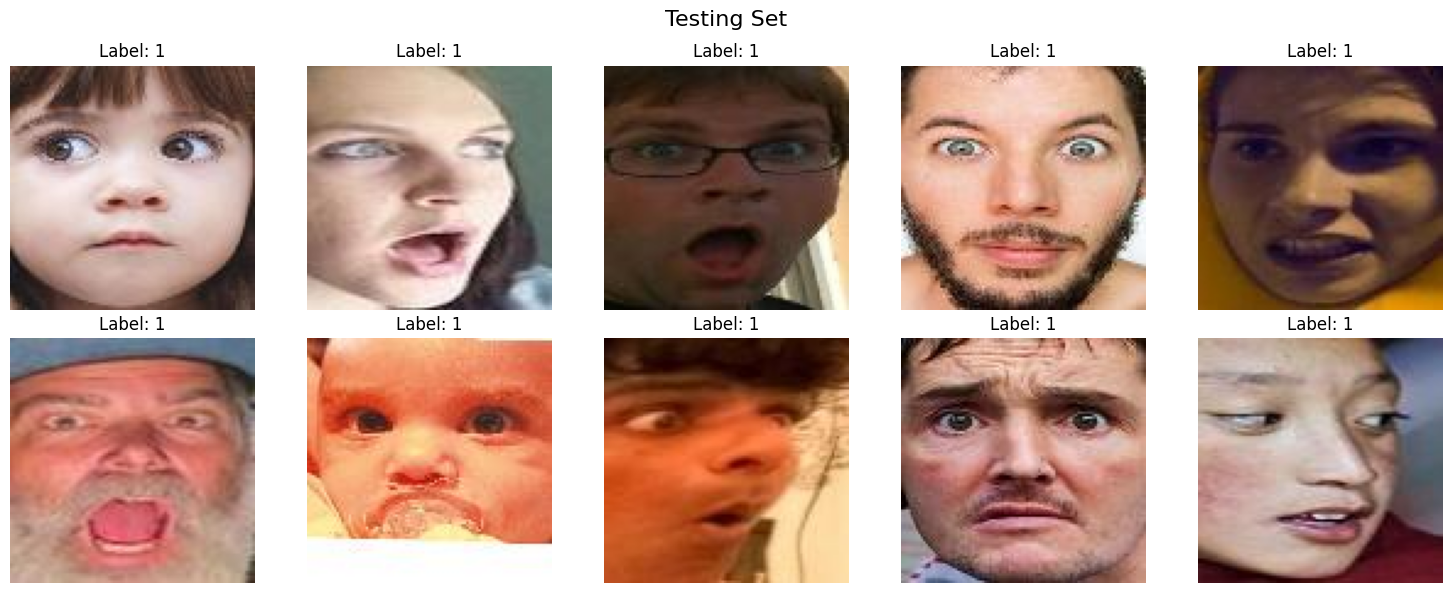

In [5]:
# Displaying the training and testing datsets (only 5 images from each dataset)

def plot_images_from_generator(generator, title, num_images=5, images_per_row=5):
    images, labels = next(generator)
    images = images[:num_images]
    labels = labels[:num_images]
    num_rows = (num_images + images_per_row - 1) // images_per_row
    fig, axes = plt.subplots(num_rows, images_per_row, figsize=(15, 3 * num_rows))
    fig.suptitle(title, fontsize=16)
    axes = axes.flatten()
    for i in range(num_images):
        img = images[i]
        label = labels[i]
        axes[i].imshow(img)
        axes[i].axis('off')
        axes[i].set_title(f"Label: {list(generator.class_indices.keys())[label.argmax()]}")
    
    for j in range(num_images, len(axes)):
        axes[j].axis('off')

    plt.tight_layout()
    plt.show()

plot_images_from_generator(traingen, "Training Set", num_images=10, images_per_row=5)
plot_images_from_generator(testgen, "Testing Set", num_images=10, images_per_row=5)

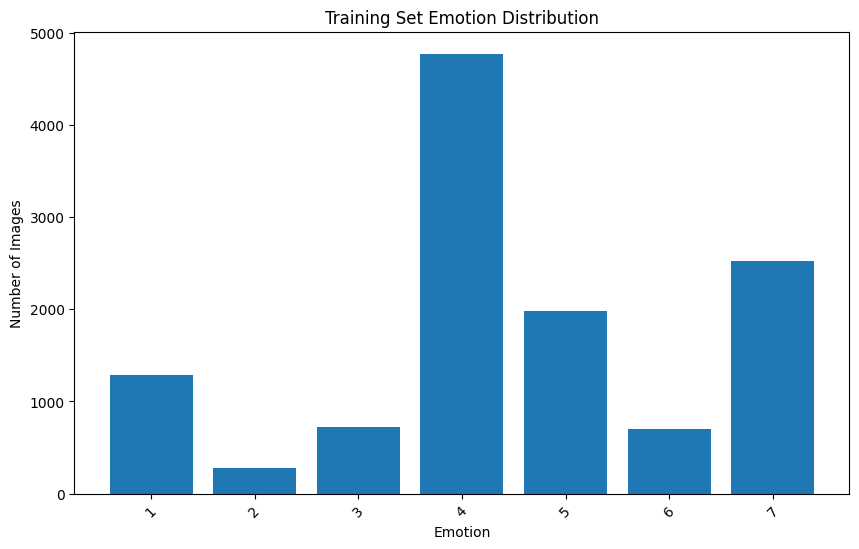

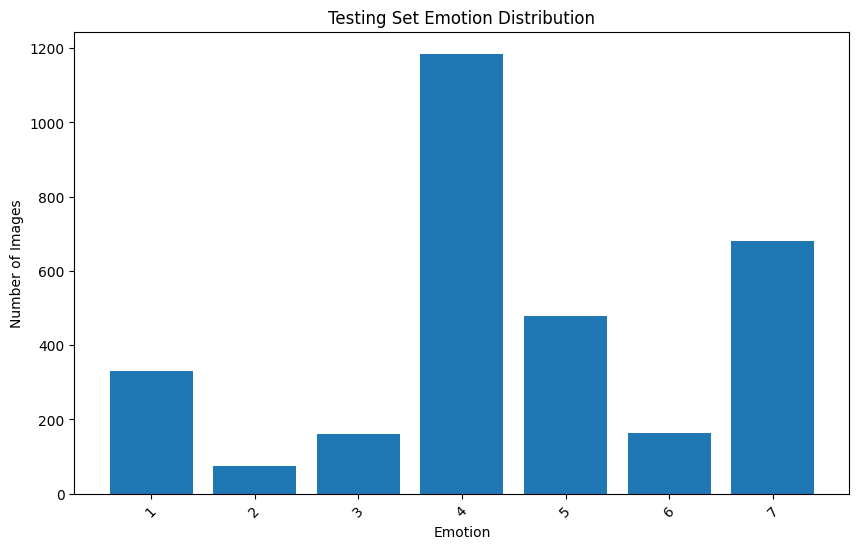

In [6]:
#class distribution

def plot_class_distribution(directory, title):
    class_names = os.listdir(directory)
    class_counts = []
    for class_name in class_names:
        class_dir = os.path.join(directory, class_name)
        if os.path.isdir(class_dir):
            class_counts.append(len(os.listdir(class_dir)))

    plt.figure(figsize=(10, 6))
    plt.bar(class_names, class_counts)
    plt.title(title)
    plt.xlabel('Emotion')
    plt.ylabel('Number of Images')
    plt.xticks(rotation=45)
    plt.show()

plot_class_distribution(train, "Training Set Emotion Distribution")
plot_class_distribution(test, "Testing Set Emotion Distribution")

In [7]:
label_map = {
    1: 'Surprise',
    2: 'Fear',
    3: 'Disgust',
    4: 'Happiness',
    5: 'Sadness',
    6: 'Anger',
    7: 'Neutral'
}

In [8]:
# Learning rate schedule for better training control

optimizer = Adam(learning_rate=0.001)

In [9]:
# Stage 2: RGB CNN
# Same CNN architecture as baseline, but using RGB input

model = Sequential()

# RGB input: 100 x 100 x 3
model.add(Input(shape=(100, 100, 3)))

# Block 1
model.add(SeparableConv2D(
    64, (3, 3),
    padding='same',
    depthwise_initializer='he_normal',
    pointwise_initializer='he_normal'
))
model.add(BatchNormalization())
model.add(Activation('relu'))

model.add(SeparableConv2D(
    64, (3, 3),
    padding='same',
    depthwise_initializer='he_normal',
    pointwise_initializer='he_normal'
))
model.add(BatchNormalization())
model.add(Activation('relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.25))


# Block 2
model.add(SeparableConv2D(
    128, (3, 3),
    padding='same',
    depthwise_initializer='he_normal',
    pointwise_initializer='he_normal'
))
model.add(BatchNormalization())
model.add(Activation('relu'))

model.add(SeparableConv2D(
    128, (3, 3),
    padding='same',
    depthwise_initializer='he_normal',
    pointwise_initializer='he_normal'
))
model.add(BatchNormalization())
model.add(Activation('relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.25))


# Block 3
model.add(SeparableConv2D(
    256, (3, 3),
    padding='same',
    depthwise_initializer='he_normal',
    pointwise_initializer='he_normal'
))
model.add(BatchNormalization())
model.add(Activation('relu'))

model.add(SeparableConv2D(
    256, (3, 3),
    padding='same',
    depthwise_initializer='he_normal',
    pointwise_initializer='he_normal'
))
model.add(BatchNormalization())
model.add(Activation('relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.25))


# Block 4
model.add(SeparableConv2D(
    512, (3, 3),
    padding='same',
    depthwise_initializer='he_normal',
    pointwise_initializer='he_normal'
))
model.add(BatchNormalization())
model.add(Activation('relu'))

model.add(SeparableConv2D(
    512, (3, 3),
    padding='same',
    depthwise_initializer='he_normal',
    pointwise_initializer='he_normal'
))
model.add(BatchNormalization())
model.add(Activation('relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.25))


# Dense layers
model.add(Flatten())

model.add(
    Dense(
        512,
        activation='relu',
        kernel_initializer='he_normal'
    )
)

model.add(BatchNormalization())
model.add(Dropout(0.5))

# 7 emotion classes
model.add(Dense(7, activation='softmax'))


# Compile
model.compile(
    optimizer=optimizer,
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ separable_conv2d                │ (None, 100, 100, 64)   │           283 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 100, 100, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 100, 100, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_1              │ (None, 100, 100, 64)   │         4,736 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 100, 100, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 100, 100, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 50, 50, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 50, 50, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_2              │ (None, 50, 50, 128)    │         8,896 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 50, 50, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 50, 50, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_3              │ (None, 50, 50, 128)    │        17,664 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 50, 50, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 50, 50, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 25, 25, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 25, 25, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_4              │ (None, 25, 25, 256)    │        34,176 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 25, 25, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 25, 25, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_5              │ (None, 25, 25, 256)    │        68,09

 Total params: 9,986,018 (38.09 MB)

 Trainable params: 9,981,154 (38.08 MB)

 Non-trainable params: 4,864 (19.00 KB)

In [10]:
import tensorflow as tf

model_path = r"Models\raf_3cnn_model.keras"

model = tf.keras.models.load_model(model_path)


In [11]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ separable_conv2d                │ (None, 100, 100, 64)   │           283 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 100, 100, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 100, 100, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_1              │ (None, 100, 100, 64)   │         4,736 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 100, 100, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 100, 100, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 50, 50, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 50, 50, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_2              │ (None, 50, 50, 128)    │         8,896 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 50, 50, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 50, 50, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_3              │ (None, 50, 50, 128)    │        17,664 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 50, 50, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 50, 50, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 25, 25, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 25, 25, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_4              │ (None, 25, 25, 256)    │        34,176 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 25, 25, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 25, 25, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_5              │ (None, 25, 25, 256)    │        68,09

 Total params: 29,948,328 (114.24 MB)

 Trainable params: 9,981,154 (38.08 MB)

 Non-trainable params: 4,864 (19.00 KB)

 Optimizer params: 19,962,310 (76.15 MB)

In [12]:
import tensorflow as tf

# ==========================================
# GET MODEL INPUT SHAPE
# ==========================================

input_shape = model.input_shape

print("Original input shape:", input_shape)

# Replace None batch dimension with 1
input_shape = (1,) + tuple(input_shape[1:])

print("FLOPs input shape:", input_shape)


# ==========================================
# CREATE DUMMY INPUT
# ==========================================

dummy_input = tf.random.normal(input_shape)


# ==========================================
# CREATE CONCRETE FUNCTION
# ==========================================

@tf.function
def model_fn(x):
    return model(x, training=False)

concrete_func = model_fn.get_concrete_function(dummy_input)


# ==========================================
# FREEZE MODEL
# ==========================================

from tensorflow.python.framework.convert_to_constants import (
    convert_variables_to_constants_v2
)

frozen_func = convert_variables_to_constants_v2(concrete_func)


# ==========================================
# GET GRAPH
# ==========================================

graph_def = frozen_func.graph.as_graph_def()


# ==========================================
# CALCULATE FLOPs
# ==========================================

with tf.Graph().as_default() as graph:

    tf.graph_util.import_graph_def(
        graph_def,
        name=""
    )

    run_meta = tf.compat.v1.RunMetadata()

    opts = tf.compat.v1.profiler.ProfileOptionBuilder.float_operation()

    flops = tf.compat.v1.profiler.profile(
        graph=graph,
        run_meta=run_meta,
        cmd="op",
        options=opts
    )


# ==========================================
# RESULTS
# ==========================================

print("\n==========================================")
print("MODEL COMPLEXITY")
print("==========================================")

print(f"Input shape : {input_shape}")
print(f"Parameters  : {model.count_params():,}")

if flops is not None:
    print(f"FLOPs       : {flops.total_float_ops:,}")
    print(f"GFLOPs      : {flops.total_float_ops / 1e9:.4f}")
else:
    print("FLOPs       : Could not be calculated")

print("==========================================")

Original input shape: (None, 100, 100, 3)
FLOPs input shape: (1, 100, 100, 3)


Instructions for updating:
This API was designed for TensorFlow v1. See https://www.tensorflow.org/guide/migrate for instructions on how to migrate your code to TensorFlow v2.

MODEL COMPLEXITY
Input shape : (1, 100, 100, 3)
Parameters  : 9,986,018
FLOPs       : 499,018,122
GFLOPs      : 0.4990


In [13]:
#Predicting
test_loss, test_accuracy = model.evaluate(testgen)

96/96 ━━━━━━━━━━━━━━━━━━━━ 131s 1s/step - accuracy: 0.8341 - loss: 0.5047


Test Accuracy: 0.83
96/96 ━━━━━━━━━━━━━━━━━━━━ 129s 1s/step
Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.84      0.86       329
           1       0.68      0.58      0.63        74
           2       0.57      0.46      0.51       160
           3       0.95      0.91      0.93      1185
           4       0.74      0.88      0.80       478
           5       0.74      0.75      0.74       162
           6       0.79      0.80      0.80       680

    accuracy                           0.83      3068
   macro avg       0.76      0.75      0.75      3068
weighted avg       0.84      0.83      0.83      3068

Confusion Matrix:
[[ 277   10    6    7    6    6   17]
 [  11   43    1    3    9    3    4]
 [   2    3   74   11   27   18   25]
 [   6    3   12 1078   20    7   59]
 [   2    1   11   11  421    4   28]
 [   5    3    8    8    7  121   10]
 [  15    0   17   18   80    5  545]] 




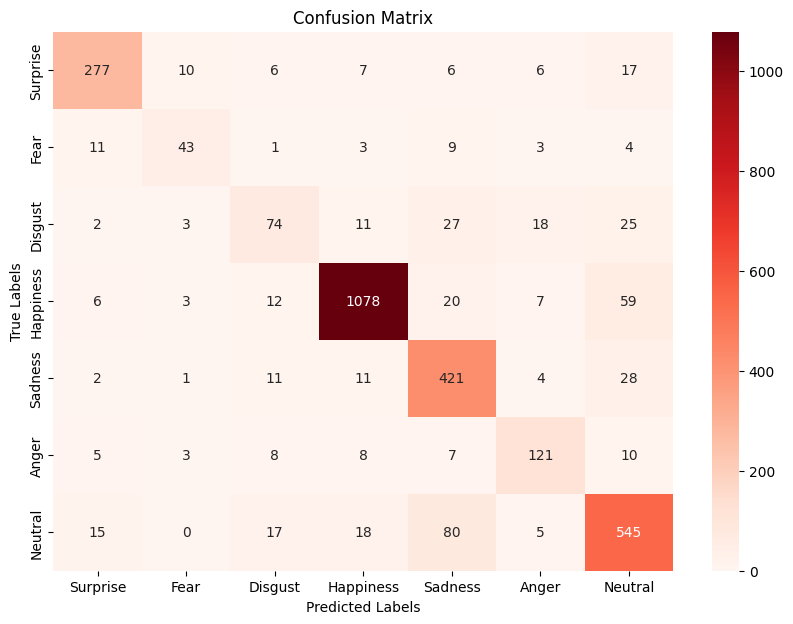

Training class indices: {'1': 0, '2': 1, '3': 2, '4': 3, '5': 4, '6': 5, '7': 6}
Test class indices: {'1': 0, '2': 1, '3': 2, '4': 3, '5': 4, '6': 5, '7': 6}


In [14]:
print(f"Test Accuracy: {test_accuracy:.2f}")
y_pred = np.argmax(model.predict(testgen), axis=1)
y_true = testgen.classes
print("Classification Report:")
print(classification_report(y_true, y_pred))
conf_matrix = confusion_matrix(y_true, y_pred)
print("Confusion Matrix:")
print(conf_matrix,'\n\n')
plt.figure(figsize=(10, 7))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Reds', 
            xticklabels=list(label_map.values()), 
            yticklabels=list(label_map.values()))
plt.title('Confusion Matrix')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()
print("Training class indices:", traingen.class_indices)
print("Test class indices:", testgen.class_indices)

In [15]:
import json

with open(r"History\deep_cnn_history.json", "r") as f:
    history_data = json.load(f)

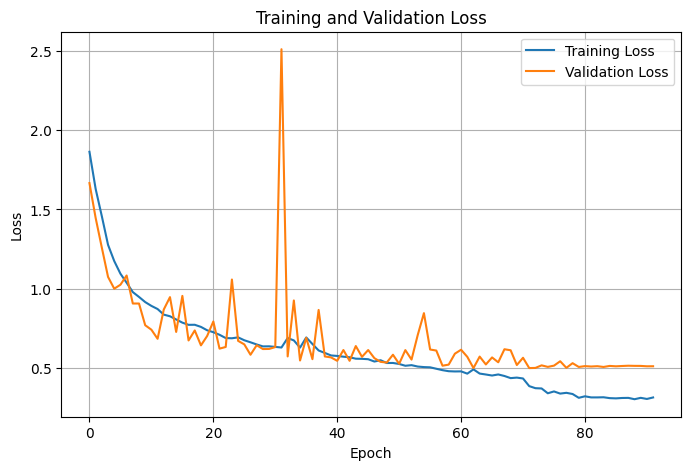

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(history_data["loss"], label="Training Loss")
plt.plot(history_data["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid()
plt.show()

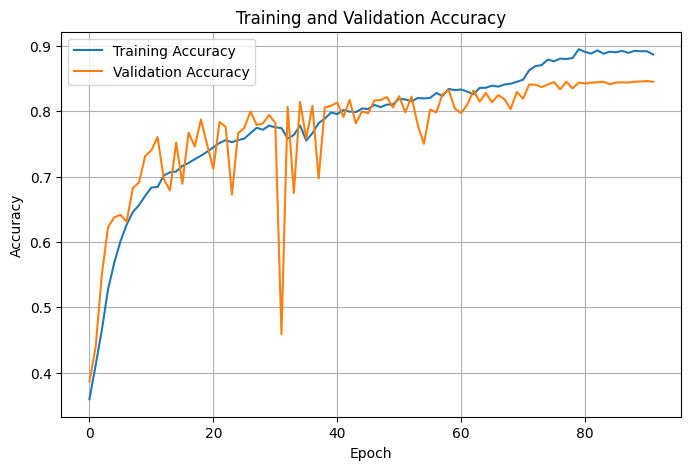

In [17]:
plt.figure(figsize=(8, 5))
plt.plot(history_data["accuracy"], label="Training Accuracy")
plt.plot(history_data["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid()
plt.show()

96/96 ━━━━━━━━━━━━━━━━━━━━ 128s 1s/step


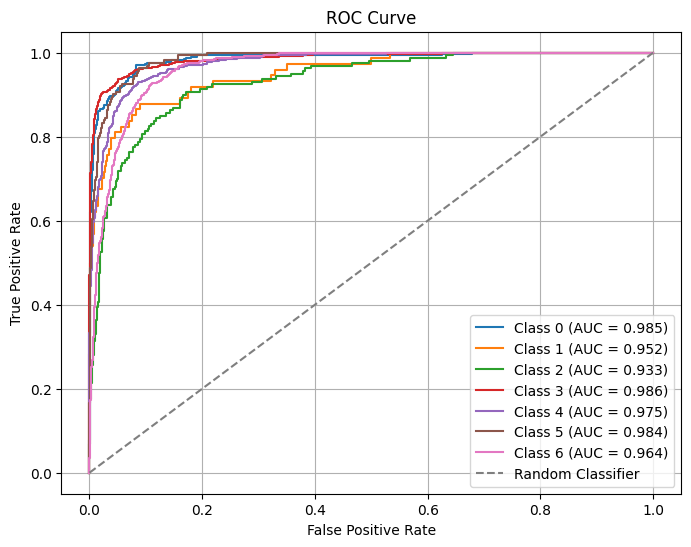

In [18]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

# Reset test generator
testgen.reset()

# Get predicted probabilities
y_score = model.predict(testgen)

# True labels
y_true = testgen.classes

# Number of classes
n_classes = y_score.shape[1]

# Convert true labels to one-hot
y_true_bin = label_binarize(
    y_true,
    classes=np.arange(n_classes)
)

# Plot ROC for each class
plt.figure(figsize=(8, 6))

for i in range(n_classes):
    fpr, tpr, _ = roc_curve(
        y_true_bin[:, i],
        y_score[:, i]
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"Class {i} (AUC = {roc_auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(loc="lower right")
plt.grid()
plt.show()